# Introduction
The purpose of Exploratory Data Analysis (EDA) is to understand the cleaned IMDB dataset before applying machine learning algorithms.

EDA will help to answer the following questions:
1. How many positive and negative reviews are present?
2. Is the dataset balanced?
3. How long are the movie reviews?
4. Which words occur most frequently?
5. Do positive and negative reviews use different words?
6. Are there any patterns or unusual observations in the text data?

# Step 1: Importing libraries
This step imports the libraries required for data analysis and visualization. Pandas and NumPy help handle data, while Matplotlib and Seaborn are used to create graphs. CountVectorizer and Counter help analyze frequently occurring words.


In [57]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os
import re
from collections import Counter
from sklearn.feature_extraction.text import CountVectorizer

# Step 2: Loading the cleaned dataset
The cleaned dataset is loaded from the processed data folder. This dataset will be used for EDA instead of the original raw dataset.


In [58]:
df = pd.read_csv("../data/processed/cleaned_dataset.csv")


# Step 3: Understanding the dataset
These operations provide an overview of the dataset, including the infrmation available, the number of rows, columns, data types and statistical information. This helps to understand the structure of the data before performing further analysis.


In [59]:
df.head()

,review,sentiment
0,One of the other reviewers has mentioned that ...,positive
1,A wonderful little production. The filming tec...,positive
2,I thought this was a wonderful way to spend ti...,positive
3,Basically there's a family where a little boy ...,negative
4,"Petter Mattei's ""Love in the Time of Money"" is...",positive


In [60]:
df.shape

(49578, 2)

In [61]:
df.columns

Index(['review', 'sentiment'], dtype='object')

In [62]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 49578 entries, 0 to 49577
Data columns (total 2 columns):
 #   Column     Non-Null Count  Dtype 
---  ------     --------------  ----- 
 0   review     49578 non-null  object
 1   sentiment  49578 non-null  object
dtypes: object(2)
memory usage: 774.8+ KB


In [63]:
df.describe(include='all')

,review,sentiment
count,49578,49578
unique,49578,2
top,One of the other reviewers has mentioned that ...,positive
freq,1,24882


# Step 4: Data analysis and visualizations
Created visualizations that explain the dataset and provide useful insights for the machine learning stage.

# Step 4.1: Sentiment distribution (Bar chart)
The bar chart shows the distribution of positive and negative reviews in the dataset. It helps identify whether the dataset is balanced or imbalanced. A balanced dataset generally provides a better starting point for sentiment classification.


In [64]:
df['sentiment'].value_counts()

sentiment
positive    24882
negative    24696
Name: count, dtype: int64

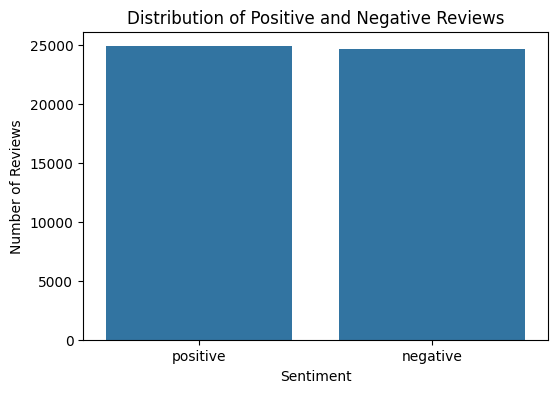

In [65]:
plt.figure(figsize=(6, 4))

sns.countplot(data=df, x='sentiment')

plt.title('Distribution of Positive and Negative Reviews')
plt.xlabel('Sentiment')
plt.ylabel('Number of Reviews')
plt.show()

# Step 4.2: Review length analysis
Understanding how long the movie reviews are.
This analysis examines the length of movie reviews using character counts. The histogram displays the distribution of review lengths, while the box plot compares review lengths between positive and negative categories. It helps identify differences and unusually long or short reviews.

In [66]:
df['review_length'] = df['review'].astype(str).apply(len)

df[['review', 'review_length']].head()

,review,review_length
0,One of the other reviewers has mentioned that ...,1728
1,A wonderful little production. The filming tec...,962
2,I thought this was a wonderful way to spend ti...,904
3,Basically there's a family where a little boy ...,715
4,"Petter Mattei's ""Love in the Time of Money"" is...",1272


In [67]:
df.groupby('sentiment')['review_length'].describe()

,count,mean,std,min,25%,50%,75%,max
sentiment,,,,,,,,
negative,24696.0,1271.559726,928.978757,32.0,697.0,958.0,1538.0,8698.0
positive,24882.0,1304.468652,1015.456699,65.0,683.0,953.0,1587.0,13593.0


# Step 4.2.1: Histogram

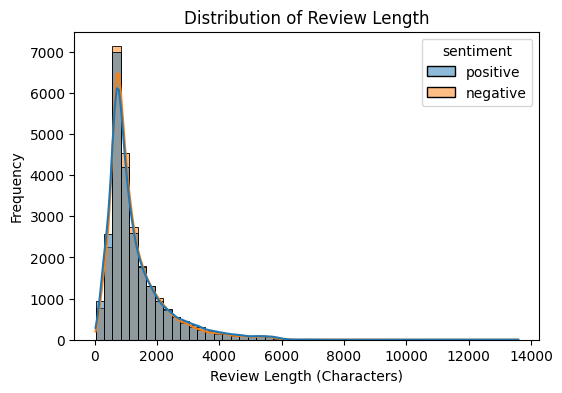

In [68]:
plt.figure(figsize=(6, 4))

sns.histplot(data=df, x='review_length',
             hue='sentiment', bins=50, kde=True)

plt.title('Distribution of Review Length')
plt.xlabel('Review Length (Characters)')
plt.ylabel('Frequency')
plt.show()

# Step 4.2.2: Box Plot

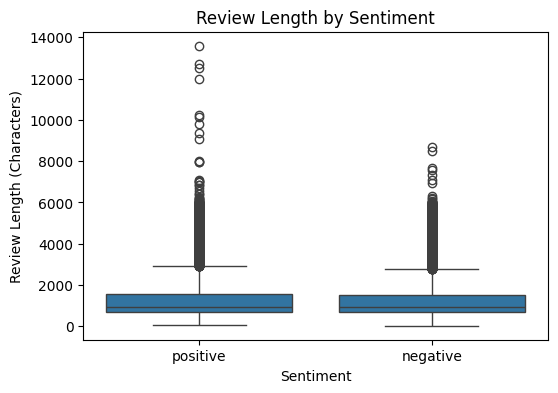

In [69]:
plt.figure(figsize=(6, 4))

sns.boxplot(data=df, x='sentiment', y='review_length')

plt.title('Review Length by Sentiment')
plt.xlabel('Sentiment')
plt.ylabel('Review Length (Characters)')
plt.show()

# Step 4.3: Most frequently occurring words
This analysis identifies the 20 most frequently occurring words in the movie reviews. Common English stopwords are removed to focus on more meaningful terms. The bar chart displays the frequency of each word and helps understand the overall vocabulary used in the reviews.

In [70]:
from sklearn.feature_extraction.text import ENGLISH_STOP_WORDS

stop_words = set(ENGLISH_STOP_WORDS)

# Preserve important negative words
stop_words.difference_update({
    'not', 'no', 'nor', 'never'
})

def get_words(text):
    text = str(text).lower()

    # Handle common negative contractions
    text = re.sub(r"\bwon't\b", "will not", text)
    text = re.sub(r"\bcan't\b", "cannot", text)
    text = re.sub(r"n't\b", " not", text)

    # Remove possessive endings
    text = re.sub(r"'s\b", "", text)

    # Extract words
    words = re.findall(r'\b[a-zA-Z]+\b', text)

    return [word for word in words if word not in stop_words]

all_words = []

for review in df['review']:
    all_words.extend(get_words(review))

word_counts = Counter(all_words)

word_counts.most_common(20)

[('not', 119186),
 ('movie', 87273),
 ('film', 79144),
 ('like', 39842),
 ('just', 34926),
 ('good', 29543),
 ('no', 25080),
 ('time', 24905),
 ('story', 22968),
 ('really', 22923),
 ('did', 21176),
 ('does', 20306),
 ('bad', 18291),
 ('people', 18022),
 ('great', 18018),
 ('make', 15780),
 ('way', 15516),
 ('movies', 15223),
 ('characters', 14321),
 ('think', 14227)]

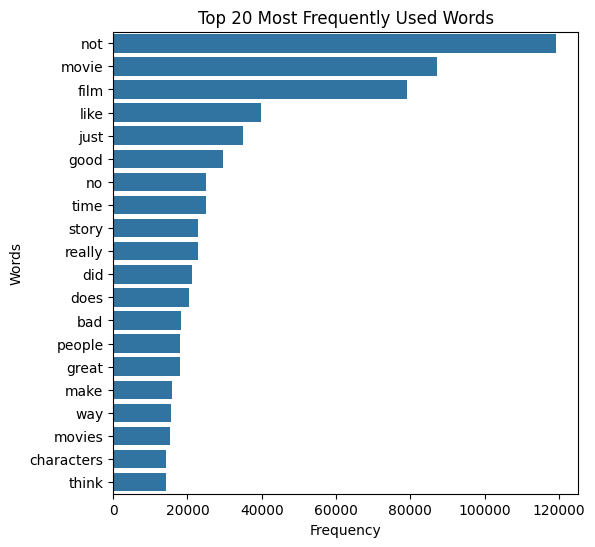

In [71]:
common_words = word_counts.most_common(20)

words_df = pd.DataFrame(
    common_words,
    columns=['Word', 'Frequency']
)

plt.figure(figsize=(6, 6))

sns.barplot(data=words_df, x='Frequency', y='Word')

plt.title('Top 20 Most Frequently Used Words')
plt.xlabel('Frequency')
plt.ylabel('Words')
plt.show()

# Step 4.4: Comparing frequently occurring words in positive and negative reviews
This analysis compares the most frequently occurring words in positive and negative movie reviews. Separate bar charts help identify differences in vocabulary between the two sentiment categories. These patterns can provide useful insights into how language is associated with sentiment.

In [72]:
positive_reviews = df[df['sentiment'] == 'positive']['review']

negative_reviews = df[df['sentiment'] == 'negative']['review']

positive_words = []

for review in positive_reviews:
    positive_words.extend(get_words(review))

negative_words = []

for review in negative_reviews:
    negative_words.extend(get_words(review))

positive_counts = Counter(positive_words)
negative_counts = Counter(negative_words)

print("Positive Reviews:")
print(positive_counts.most_common(15))

print("\nNegative Reviews:")
print(negative_counts.most_common(15))

Positive Reviews:
[('not', 51863), ('film', 41966), ('movie', 37660), ('like', 17651), ('good', 14964), ('just', 14057), ('story', 12896), ('great', 12889), ('time', 12701), ('really', 10706), ('does', 9627), ('no', 9196), ('did', 8875), ('people', 8685), ('love', 8658)]

Negative Reviews:
[('not', 67323), ('movie', 49613), ('film', 37178), ('like', 22191), ('just', 20869), ('no', 15884), ('good', 14579), ('bad', 14562), ('did', 12301), ('really', 12217), ('time', 12204), ('does', 10679), ('story', 10072), ('people', 9337), ('make', 9264)]


# Step 4.4.1: Positive Reviews

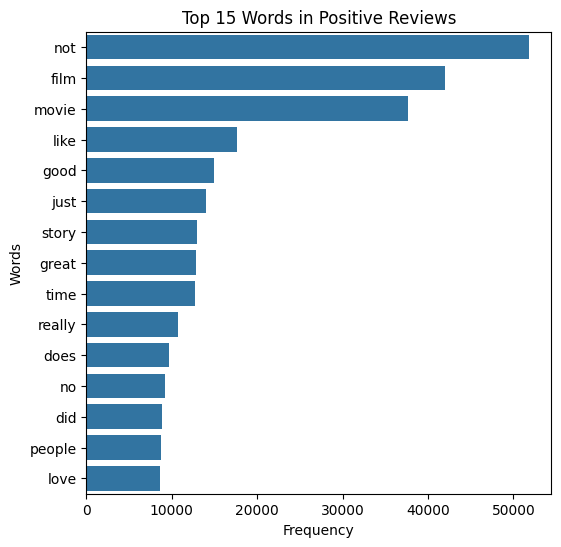

In [73]:
positive_df = pd.DataFrame(
    positive_counts.most_common(15),
    columns=['Word', 'Frequency']
)

plt.figure(figsize=(6, 6))

sns.barplot(data=positive_df, x='Frequency', y='Word')

plt.title('Top 15 Words in Positive Reviews')
plt.xlabel('Frequency')
plt.ylabel('Words')
plt.show()

# Step 4.4.2: Negative Reviews

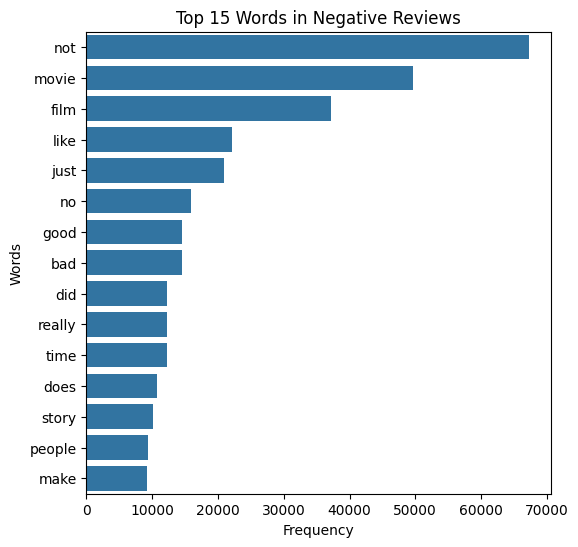

In [74]:
negative_df = pd.DataFrame(
    negative_counts.most_common(15),
    columns=['Word', 'Frequency']
)

plt.figure(figsize=(6, 6))

sns.barplot(data=negative_df, x='Frequency', y='Word')

plt.title('Top 15 Words in Negative Reviews')
plt.xlabel('Frequency')
plt.ylabel('Words')
plt.show()

# Step 4.5: Bigram analysis (Frequently occurring word combinations)
Bigram analysis identifies frequently occurring pairs of consecutive words in movie reviews. It provides more context than individual word frequency analysis and helps identify common expressions used by reviewers

In [75]:
positive_reviews = df[df['sentiment'] == 'positive']['review'].apply(clean_bigrams)

negative_reviews = df[df['sentiment'] == 'negative']['review'].apply(clean_bigrams)

In [76]:
def get_top_bigrams(reviews):

    vectorizer = CountVectorizer(
        stop_words=list(stop_words),
        ngram_range=(2, 2),
        max_features=20
    )

    matrix = vectorizer.fit_transform(reviews)

    bigram_df = pd.DataFrame({
        'Bigram': vectorizer.get_feature_names_out(),
        'Frequency': matrix.sum(axis=0).A1
    })

    return bigram_df.sort_values(
        by='Frequency', ascending=False
    ).reset_index(drop=True)

In [77]:
positive_bigrams = get_top_bigrams(positive_reviews)

negative_bigrams = get_top_bigrams(negative_reviews)

# Step 4.5.1: Positive Reviews

In [78]:
print("Positive Review Bigrams:")
display(positive_bigrams)

Positive Review Bigrams:


,Bigram,Frequency
0,does not,4933
1,did not,4338
2,not know,1557
3,movie not,1472
4,film not,1381
5,not like,1093
6,not really,1017
7,new york,854
8,not seen,845
9,not think,827


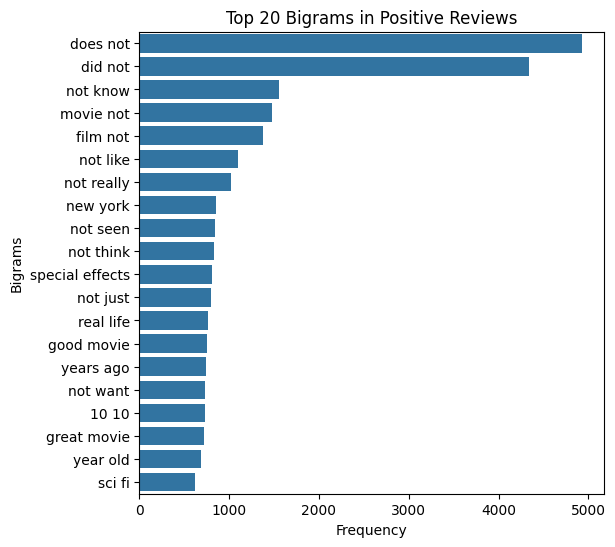

In [79]:
plt.figure(figsize=(6, 6))

sns.barplot(
    data=positive_bigrams,
    x='Frequency',
    y='Bigram'
)

plt.title('Top 20 Bigrams in Positive Reviews')
plt.xlabel('Frequency')
plt.ylabel('Bigrams')

plt.show()

# Step 4.5.2: Negative Reviews

In [80]:
print("Negative Review Bigrams:")
display(negative_bigrams)

Negative Review Bigrams:


,Bigram,Frequency
0,did not,6718
1,does not,6505
2,movie not,2147
3,not know,2039
4,special effects,1433
5,waste time,1429
6,not good,1404
7,not really,1380
8,just not,1350
9,film not,1317


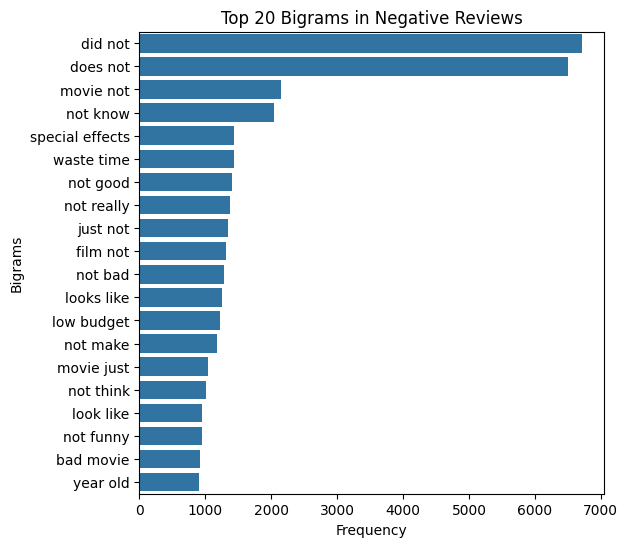

In [81]:
plt.figure(figsize=(6, 6))

sns.barplot(
    data=negative_bigrams,
    x='Frequency',
    y='Bigram'
)

plt.title('Top 20 Bigrams in Negative Reviews')
plt.xlabel('Frequency')
plt.ylabel('Bigrams')

plt.show()

# Final EDA Summary
1. The dataset contains both positive and negative movie reviews.
2. The sentiment distribution indicates whether the dataset is balanced.
3. Review length analysis shows variations in the number of characters.
4. Word frequency analysis identifies commonly used terms in movie reviews.
5. Positive and negative reviews show differences in frequently used vocabulary.
6. Bigram analysis highlights common combinations of words in both positive and negative reviews.

These observations provide an understanding of the dataset and helps to prepare it for sentiment classification using machine learning algorithms.